In [17]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [18]:
ann_vars = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/results/expecto_annotated_variants.csv")
ann_vars["abs_mean_z_gt1"] = ann_vars["mean_z"].abs() > 1
ann_vars
concordant_vars = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/workflow/notebooks/concordant_variants_breast_epithelial.csv")
SELECT_SNPs = concordant_vars['SNP']
SELECT_SNPs

con_ann_var = ann_vars[ann_vars['SNP'].isin(SELECT_SNPs)].reset_index(drop=True)
con_ann_var
ann_vars['sig_hit'] = ann_vars['SNP'].isin(SELECT_SNPs)
ann_vars

,chrom,snp_chromStart,snp_chromEnd,SNP,ref,alt,chrom_gene,tss,tss_chromEnd,strand,...,Fibro_SFRP4,Lumsec_HLA,Mono_non_classical,LummHR_active,Macro_IFN,CD4_activated,Fibro_major,pDC,abs_mean_z_gt1,sig_hit
0,1,45794979,45794980,1_45794979_C_G,C,G,1,45792568,45792569,+,...,-0.202274,-0.101641,-0.034030,-0.114761,-0.046459,-0.035442,-0.163672,-0.082305,False,False
1,1,45794983,45794984,1_45794983_G_A,G,A,1,45792568,45792569,+,...,0.158286,-0.343143,0.071504,-0.189323,0.095811,-0.039422,0.146556,0.040003,False,False
2,1,45794993,45794994,1_45794993_G_A,G,A,1,45792568,45792569,+,...,-0.525595,-0.224855,-0.117842,-0.203701,-0.158149,-0.265682,-0.417115,-0.308078,False,False
3,1,45794998,45794999,1_45794998_G_C,G,C,1,45792568,45792569,+,...,0.037675,0.088051,0.004546,0.093291,0.009438,0.037924,0.036089,0.015332,False,False
4,1,45795002,45795003,1_45795002_G_A,G,A,1,45792568,45792569,+,...,0.095924,0.184090,0.052263,0.155310,0.050283,-0.003054,0.116481,0.039094,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10116,8,90996799,90996800,8_90996799_T_A,T,A,8,90996871,90996872,-,...,-0.753059,0.088084,-0.440934,0.022356,-0.395922,0.338504,-0.713791,-0.032397,False,False
10117,8,90996805,90996806,8_90996805_G_A,G,A,8,90996871,90996872,-,...,-0.200781,-0.274405,-0.373441,-0.157192,-0.629108,0.134022,-0.226881,-0.418884,False,False
10118,8,90996810,90996811,8_90996810_G_A,G,A,8,90996871,90996872,-,...,0.250662,0.539204,-0.102425,0.595538,-0.173763,0.941237,0.069983,0.282454,False,False
10119,8,90996815,90996816,8_90996815_C_T,C,T,8,90996871,90996872,-,...,0.964517,1.646350,0.322142,1.211496,0.695169,1.030406,0.798057,0.799901,False,False


In [19]:
con_ann_var['feature_type'].value_counts()

feature_type
exonic_CDS    417
exonic_UTR    145
intronic       66
intergenic      6
exonic          3
Name: count, dtype: int64

In [20]:
con_ann_var['feature_type'].value_counts()                  # counts


feature_type
exonic_CDS    417
exonic_UTR    145
intronic       66
intergenic      6
exonic          3
Name: count, dtype: int64

In [21]:
# Two columns crossed, e.g. feature type per gene
pd.crosstab(con_ann_var['gene_name'], con_ann_var['feature_type'])


feature_type,exonic,exonic_CDS,exonic_UTR,intergenic,intronic
gene_name,,,,,
ATM,0,3,6,0,1
BARD1,0,12,0,0,1
BRCA1,0,4,18,0,5
BRCA2,0,1,4,0,5
BRIP1,0,3,5,1,0
CDH1,0,11,0,1,5
CHEK2,0,0,2,0,2
FANCM,1,55,0,1,0
GEN1,0,4,0,0,1


In [22]:
con_ann_var[con_ann_var['feature_type'] == 'intergenic']

,chrom,snp_chromStart,snp_chromEnd,SNP,ref,alt,chrom_gene,tss,tss_chromEnd,strand,...,plasma_IgA,Fibro_SFRP4,Lumsec_HLA,Mono_non_classical,LummHR_active,Macro_IFN,CD4_activated,Fibro_major,pDC,abs_mean_z_gt1
91,14,45605022,45605023,14_45605022_G_T,G,T,14,45605171,45605172,+,...,-11.703478,-3.528050,-6.450133,-17.669361,-8.399136,-13.346352,-18.119098,-1.162547,-12.059610,True
220,16,68771122,68771123,16_68771122_A_C,A,C,16,68771194,68771195,+,...,0.168039,0.717388,-3.075412,0.191699,-1.582829,0.292568,-0.559026,0.429362,-0.198205,False
314,17,59940921,59940922,17_59940921_C_T,C,T,17,59940863,59940864,-,...,-2.014720,-3.308374,-3.003061,-2.891111,-3.725860,-2.330552,-4.101705,-2.652375,-2.643928,True
346,2,47630103,47630104,2_47630103_C_T,C,T,2,47630294,47630295,+,...,-9.966418,-23.066232,-8.402386,-16.851162,-7.731449,-15.800177,-16.016232,-22.385846,-16.573160,True
347,2,47630106,47630107,2_47630106_G_C,G,C,2,47630294,47630295,+,...,-1.652390,-8.350991,-5.163354,-2.834732,-5.002389,-3.610380,-3.307618,-7.516194,-3.464657,True
496,3,37034819,37034820,3_37034819_A_G,A,G,3,37035003,37035004,+,...,-1.059568,-1.029847,-1.676962,-0.557133,-1.657971,-1.057279,-1.999897,-0.551656,-2.541600,True


<Axes: xlabel='feature_type', ylabel='max_abs_z'>

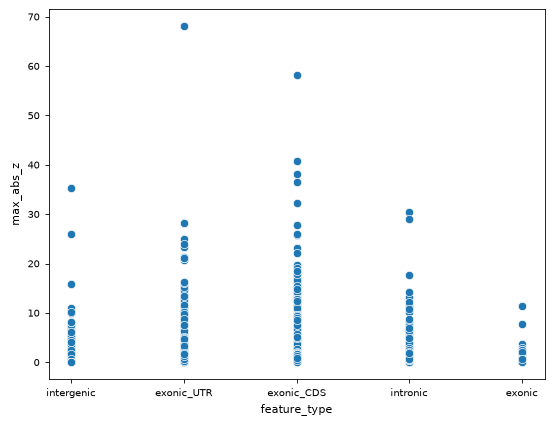

In [23]:
sns.scatterplot(
    x='feature_type',
    y='max_abs_z',
    data=ann_vars
)

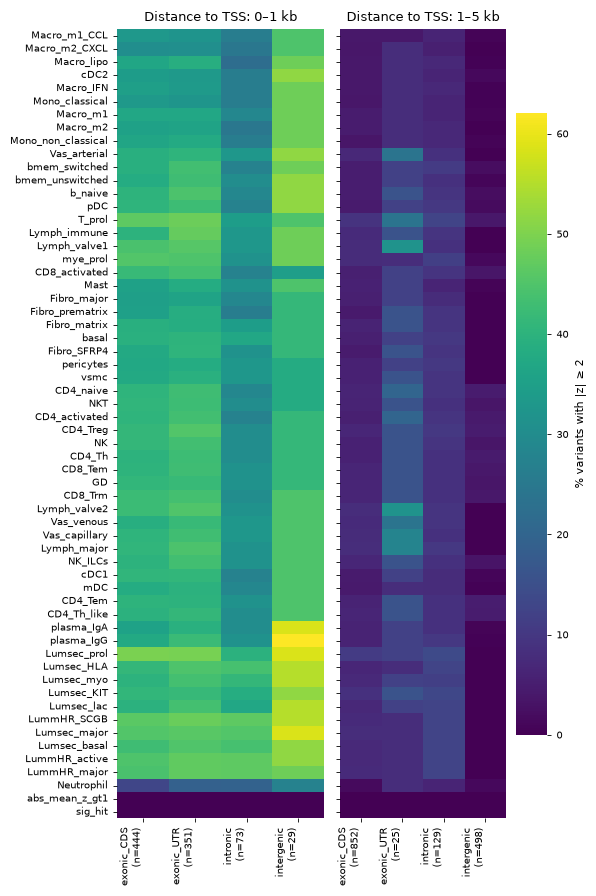

In [24]:
meta_end = ann_vars.columns.get_loc("n_celltypes_abs_z_ge_2")
cell_cols = [c for c in ann_vars.columns[meta_end + 1:] if c != "macro_mean"]  # macro_mean is ~0 everywhere

ann_vars["dist_bin"] = pd.cut(ann_vars["dist"], [-1, 1000, 5000, np.inf],
                              labels=["0–1 kb", "1–5 kb", ">5 kb"])
long = ann_vars.melt(id_vars=["SNP", "feature_type", "dist_bin"], value_vars=cell_cols,
                     var_name="cell_type", value_name="z")
long["hit"] = long["z"].abs() >= 2

ft_order = ["exonic_CDS", "exonic_UTR", "intronic", "intergenic"]  # "exonic" has n=4 within 1 kb
bins = ["0–1 kb", "1–5 kb"]

frac = (long.groupby(["dist_bin", "cell_type", "feature_type"], observed=True)["hit"]
            .mean().mul(100).unstack("feature_type")[ft_order])
n = ann_vars.groupby(["dist_bin", "feature_type"], observed=True).size().unstack()[ft_order]

# order cell types by clustering the 0–1 kb profile
row_order = sns.clustermap(frac.loc["0–1 kb"].fillna(0), col_cluster=False).dendrogram_row.reordered_ind
row_order = frac.loc["0–1 kb"].index[row_order]
plt.close("all")

vmax = frac.loc[bins].max().max()
fig, axes = plt.subplots(1, len(bins), figsize=(6, 9), sharey=True)
for ax, b in zip(axes, bins):
    sns.heatmap(frac.loc[b].reindex(row_order), ax=ax, cmap="viridis", vmin=0, vmax=vmax,
                yticklabels=True, cbar=ax is axes[-1],
                cbar_kws={"label": "% variants with |z| ≥ 2"})
    ax.tick_params(axis="y", labelsize=7)
    ax.set_xticklabels([f"{f}\n(n={int(n.loc[b, f])})" for f in ft_order], rotation=90, ha="right")
    ax.set_title(f"Distance to TSS: {b}"); ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout()
fig.tight_layout()
fig.savefig("cell_type_z_score_tss.pdf", dpi=600)
fig.savefig("cell_type_z_score_tss.png", dpi=300)


In [25]:
ann_vars.columns

Index(['chrom', 'snp_chromStart', 'snp_chromEnd', 'SNP', 'ref', 'alt',
       'chrom_gene', 'tss', 'tss_chromEnd', 'strand', 'gene_name', 'gene_id',
       'cage_used', 'dist', 'feature_type', 'overlapping_transcripts',
       'genes_overlapping_variant', 'position_vs_tss', 'max_abs_z',
       'max_abs_z_celltype', 'mean_z', 'n_celltypes_abs_z_ge_2',
       'Lumsec_major', 'CD4_naive', 'Vas_arterial', 'T_prol', 'Lymph_valve2',
       'Vas_venous', 'pericytes', 'Lumsec_myo', 'CD8_Tem', 'macro_mean',
       'b_naive', 'Lumsec_basal', 'CD8_activated', 'Lymph_valve1',
       'Fibro_prematrix', 'Lymph_major', 'CD4_Tem', 'plasma_IgG', 'mDC',
       'CD8_Trm', 'bmem_unswitched', 'CD4_Th_like', 'mye_prol', 'basal',
       'Neutrophil', 'Mono_classical', 'LummHR_major', 'GD', 'Mast', 'NK',
       'Macro_lipo', 'LummHR_SCGB', 'CD4_Treg', 'Lymph_immune', 'cDC1',
       'Macro_m1', 'Fibro_matrix', 'Lumsec_KIT', 'NKT', 'Lumsec_lac',
       'Vas_capillary', 'bmem_switched', 'Macro_m2_CXCL', 'NK_ILCs

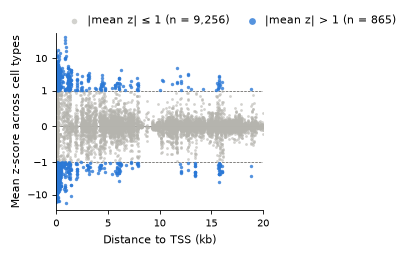

In [26]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "pdf.fonttype": 42, "ps.fonttype": 42,  # keep text editable in Illustrator
})

fig, ax = plt.subplots(figsize=(3.5, 2.6))  # single-column journal width

bg = ann_vars[~ann_vars["abs_mean_z_gt1"]]
hi = ann_vars[ann_vars["abs_mean_z_gt1"]]
ax.scatter(bg["dist"] / 1e3, bg["mean_z"], s=4, c="#b5b4ae", lw=0, alpha=0.6,
           rasterized=True, label=f"|mean z| ≤ 1 (n = {len(bg):,})")
ax.scatter(hi["dist"] / 1e3, hi["mean_z"], s=6, c="#2a78d6", lw=0, alpha=0.8,
           rasterized=True, label=f"|mean z| > 1 (n = {len(hi):,})")

for y in (-1, 1):
    ax.axhline(y, color="#52514e", lw=0.5, ls="--", zorder=0)
ax.axhline(0, color="#52514e", lw=0.5, zorder=0)

ax.set_yscale("symlog", linthresh=1)
ax.set_ylim(-30, 60)
ax.set_yticks([-10, -1, 0, 1, 10])
ax.set_yticklabels(["−10", "−1", "0", "1", "10"])
ax.set_xticks(range(0, 21, 5))
ax.set_xlim(0, ann_vars["dist"].max() / 1e3)
ax.set_xlabel("Distance to TSS (kb)")
ax.set_ylabel("Mean z-score across cell types")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2,
          markerscale=2, handletextpad=0.2, columnspacing=1.0, borderaxespad=0.2)

fig.tight_layout()
fig.savefig("mean_z_vs_dist.pdf", dpi=600)
fig.savefig("mean_z_vs_dist.png", dpi=300)


In [27]:
meta_cols = ['chrom', 'snp_chromStart', 'snp_chromEnd', 'SNP', 'ref', 'alt',
                'chrom_gene', 'tss', 'tss_chromEnd', 'strand', 'gene_name', 'gene_id',
                'cage_used', 'dist', 'feature_type', 'overlapping_transcripts',
                'genes_overlapping_variant', 'position_vs_tss', 'max_abs_z',
                'max_abs_z_celltype', 'mean_z', 'n_celltypes_abs_z_ge_2'
                ]

cell_cols = ['Vas_venous', 'pericytes', 'Lumsec_myo', 'CD8_Tem', 'macro_mean',
       'b_naive', 'Lumsec_basal', 'CD8_activated', 'Lymph_valve1',
       'Fibro_prematrix', 'Lymph_major', 'CD4_Tem', 'plasma_IgG', 'mDC',
       'CD8_Trm', 'bmem_unswitched', 'CD4_Th_like', 'mye_prol', 'basal',
       'Neutrophil', 'Mono_classical', 'LummHR_major', 'GD', 'Mast', 'NK',
       'Macro_lipo', 'LummHR_SCGB', 'CD4_Treg', 'Lymph_immune', 'cDC1',
       'Macro_m1', 'Fibro_matrix', 'Lumsec_KIT', 'NKT', 'Lumsec_lac',
       'Vas_capillary', 'bmem_switched', 'Macro_m2_CXCL', 'NK_ILCs',
       'Macro_m2', 'vsmc', 'Lumsec_prol', 'CD4_Th', 'cDC2', 'Macro_m1_CCL',
       'plasma_IgA', 'Fibro_SFRP4', 'Lumsec_HLA', 'Mono_non_classical',
       'LummHR_active', 'Macro_IFN', 'CD4_activated', 'Fibro_major', 'pDC']


ann_vars_long = pd.melt(ann_vars, 
                        id_vars=meta_cols, 
                        value_vars=cell_cols,
                        var_name='cell_type',
                        value_name='z_score'
                        )
ann_vars_long

,chrom,snp_chromStart,snp_chromEnd,SNP,ref,alt,chrom_gene,tss,tss_chromEnd,strand,...,feature_type,overlapping_transcripts,genes_overlapping_variant,position_vs_tss,max_abs_z,max_abs_z_celltype,mean_z,n_celltypes_abs_z_ge_2,cell_type,z_score
0,1,45794979,45794980,1_45794979_C_G,C,G,1,45792568,45792569,+,...,intergenic,NaN,ENSG00000132781,downstream,0.202274,Fibro_SFRP4,-0.085161,0,Vas_venous,-0.097775
1,1,45794983,45794984,1_45794983_G_A,G,A,1,45792568,45792569,+,...,intergenic,NaN,ENSG00000132781,downstream,0.343143,Lumsec_HLA,-0.011812,0,Vas_venous,0.007582
2,1,45794993,45794994,1_45794993_G_A,G,A,1,45792568,45792569,+,...,intergenic,NaN,ENSG00000132781,downstream,0.525595,Fibro_SFRP4,-0.256749,0,Vas_venous,-0.284952
3,1,45794998,45794999,1_45794998_G_C,G,C,1,45792568,45792569,+,...,intergenic,NaN,ENSG00000132781,downstream,0.095425,LummHR_SCGB,0.037800,0,Vas_venous,0.050949
4,1,45795002,45795003,1_45795002_G_A,G,A,1,45792568,45792569,+,...,intergenic,NaN,ENSG00000132781,downstream,0.188081,Lymph_valve2,0.078857,0,Vas_venous,0.116439
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
546529,8,90996799,90996800,8_90996799_T_A,T,A,8,90996871,90996872,-,...,exonic_UTR,ENST00000265433;ENST00000396252;ENST0000049480...,ENSG00000104320,downstream,0.780899,Fibro_prematrix,-0.122596,0,pDC,-0.032397
546530,8,90996805,90996806,8_90996805_G_A,G,A,8,90996871,90996872,-,...,exonic_UTR,ENST00000265433;ENST00000396252;ENST0000049480...,ENSG00000104320,downstream,0.717763,mDC,-0.228630,0,pDC,-0.418884
546531,8,90996810,90996811,8_90996810_G_A,G,A,8,90996871,90996872,-,...,exonic_UTR,ENST00000265433;ENST00000396252;ENST0000049480...,ENSG00000104320,downstream,1.174331,CD8_activated,0.375588,0,pDC,0.282454
546532,8,90996815,90996816,8_90996815_C_T,C,T,8,90996871,90996872,-,...,exonic_UTR,ENST00000265433;ENST00000396252;ENST0000049480...,ENSG00000104320,downstream,1.790044,Lumsec_basal,0.979325,0,pDC,0.799901


In [28]:
ann_vars

,chrom,snp_chromStart,snp_chromEnd,SNP,ref,alt,chrom_gene,tss,tss_chromEnd,strand,...,Lumsec_HLA,Mono_non_classical,LummHR_active,Macro_IFN,CD4_activated,Fibro_major,pDC,abs_mean_z_gt1,sig_hit,dist_bin
0,1,45794979,45794980,1_45794979_C_G,C,G,1,45792568,45792569,+,...,-0.101641,-0.034030,-0.114761,-0.046459,-0.035442,-0.163672,-0.082305,False,False,1–5 kb
1,1,45794983,45794984,1_45794983_G_A,G,A,1,45792568,45792569,+,...,-0.343143,0.071504,-0.189323,0.095811,-0.039422,0.146556,0.040003,False,False,1–5 kb
2,1,45794993,45794994,1_45794993_G_A,G,A,1,45792568,45792569,+,...,-0.224855,-0.117842,-0.203701,-0.158149,-0.265682,-0.417115,-0.308078,False,False,1–5 kb
3,1,45794998,45794999,1_45794998_G_C,G,C,1,45792568,45792569,+,...,0.088051,0.004546,0.093291,0.009438,0.037924,0.036089,0.015332,False,False,1–5 kb
4,1,45795002,45795003,1_45795002_G_A,G,A,1,45792568,45792569,+,...,0.184090,0.052263,0.155310,0.050283,-0.003054,0.116481,0.039094,False,False,1–5 kb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10116,8,90996799,90996800,8_90996799_T_A,T,A,8,90996871,90996872,-,...,0.088084,-0.440934,0.022356,-0.395922,0.338504,-0.713791,-0.032397,False,False,0–1 kb
10117,8,90996805,90996806,8_90996805_G_A,G,A,8,90996871,90996872,-,...,-0.274405,-0.373441,-0.157192,-0.629108,0.134022,-0.226881,-0.418884,False,False,0–1 kb
10118,8,90996810,90996811,8_90996810_G_A,G,A,8,90996871,90996872,-,...,0.539204,-0.102425,0.595538,-0.173763,0.941237,0.069983,0.282454,False,False,0–1 kb
10119,8,90996815,90996816,8_90996815_C_T,C,T,8,90996871,90996872,-,...,1.646350,0.322142,1.211496,0.695169,1.030406,0.798057,0.799901,False,False,0–1 kb


In [29]:
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf

hit = ann_vars["sig_hit"].astype(bool)
H, N = hit.sum(), len(ann_vars)

# 1. Raw per-category Fisher test: hits vs non-hits
rows = []
for f, grp in ann_vars.groupby("feature_type"):
    a = grp["sig_hit"].sum()          # hits in f
    b = H - a                         # hits not in f
    c = len(grp) - a                  # non-hits in f
    d = (N - H) - c                   # non-hits not in f
    OR, p = fisher_exact([[a, b], [c, d]])
    rows.append({"feature_type": f, "hits": a, "hit_pct": 100 * a / H,
                 "all": len(grp), "all_pct": 100 * len(grp) / N,
                 "hit_rate_pct": 100 * a / len(grp), "odds_ratio": OR, "p": p})
enrich = pd.DataFrame(rows).sort_values("all", ascending=False)
enrich["q"] = multipletests(enrich["p"], method="fdr_bh")[1]
display(enrich.round(3))

# 2. Distance-stratified hit rates
ann_vars["dist_bin"] = pd.cut(ann_vars["dist"], [-1, 1000, 5000, np.inf],
                              labels=["0–1 kb", "1–5 kb", ">5 kb"])
display(ann_vars.pivot_table(index="feature_type", columns="dist_bin", values="sig_hit",
                             aggfunc="mean", observed=True).mul(100).round(1))

# 3. Feature effect adjusted for distance (reference = CDS)
m = smf.logit("sig_hit ~ C(feature_type, Treatment('exonic_CDS')) + np.log10(dist + 1)",
              data=ann_vars.assign(sig_hit=hit.astype(int))).fit(disp=0)
adj = pd.DataFrame({"adj_OR": np.exp(m.params), "p": m.pvalues}).join(
    np.exp(m.conf_int()).rename(columns={0: "CI_low", 1: "CI_high"}))
display(adj.round(3))


,feature_type,hits,hit_pct,all,all_pct,hit_rate_pct,odds_ratio,p,q
1,exonic_CDS,417,65.463,5652,55.844,7.378,1.538,0.000,0.000
3,intergenic,6,0.942,3012,29.760,0.199,0.020,0.000,0.000
4,intronic,66,10.361,849,8.388,7.774,1.284,0.065,0.081
2,exonic_UTR,145,22.763,482,4.762,30.083,7.999,0.000,0.000
0,exonic,3,0.471,126,1.245,2.381,0.360,0.092,0.092


dist_bin,0–1 kb,1–5 kb,>5 kb
feature_type,,,
exonic,0.0,25.0,0.9
exonic_CDS,44.8,14.0,2.3
exonic_UTR,40.5,12.0,0.0
intergenic,20.7,0.0,0.0
intronic,34.2,16.3,3.1


,adj_OR,p,CI_low,CI_high
Intercept,39.171,0.000,25.747,59.595
"C(feature_type, Treatment('exonic_CDS'))[T.exonic]",0.397,0.134,0.119,1.327
"C(feature_type, Treatment('exonic_CDS'))[T.exonic_UTR]",0.369,0.000,0.269,0.506
"C(feature_type, Treatment('exonic_CDS'))[T.intergenic]",0.035,0.000,0.015,0.078
"C(feature_type, Treatment('exonic_CDS'))[T.intronic]",1.005,0.975,0.743,1.358
np.log10(dist + 1),0.177,0.000,0.157,0.200


In [30]:
import re
import subprocess
from functools import lru_cache

from matplotlib.ticker import FuncFormatter, MaxNLocator

GTF = "/storage/mathelierarea/processed/eirikhoy/action_var/resources/Homo_sapiens.GRCh37.87.gtf.gz"

POS, NEG, NS, INK = "#e34948", "#2a78d6", "#b5b4ae", "#52514e"


@lru_cache(maxsize=None)
def load_gene_models(gene, gtf=GTF):
    """Transcript / exon / CDS rows for one gene from the Ensembl GTF."""
    out = subprocess.run(f"zcat {gtf} | grep -F 'gene_name \"{gene}\";'",
                         shell=True, capture_output=True, text=True).stdout
    rows = []
    for line in out.splitlines():
        f = line.split("\t")
        if f[2] not in ("transcript", "exon", "CDS"):
            continue
        attr = dict(re.findall(r'(\S+) "([^"]*)"', f[8]))
        rows.append({"chrom": f[0], "feature": f[2], "start": int(f[3]), "end": int(f[4]),
                     "strand": f[6], "transcript_id": attr["transcript_id"],
                     "transcript_name": attr.get("transcript_name", attr["transcript_id"]),
                     "biotype": attr.get("transcript_biotype", ""),
                     "ccds": 'tag "CCDS"' in f[8]})
    if not rows:
        raise ValueError(f"{gene} not found in {gtf}")
    return pd.DataFrame(rows)


def plot_gene_track(gene, df, score="mean_z", celltypes=None, highlight=None,
                    window=None, pad=1000, z_thresh=1, n_labels=5,
                    transcripts="protein_coding", max_transcripts=5,
                    symlog=True, gtf=GTF, figsize=(7, 4)):
    """
    Genome track for one gene: variant z-scores as a lollipop "peak" track
    above the Ensembl gene model.

    Parameters
    ----------
    gene : str
        Gene name, as in df['gene_name'] and the GTF.
    df : pd.DataFrame
        Wide variant table (e.g. ann_vars): SNP, snp_chromStart, gene_name,
        tss, cage_used and one z-score column per cell type.
    score : str
        Column to plot (e.g. 'mean_z', 'max_abs_z' or a single cell type).
        Ignored if `celltypes` is given.
    celltypes : list, optional
        Plot the mean z-score across these cell types instead of `score`
        (e.g. the breast epithelial set).
    highlight : iterable of SNP ids, optional
        Variants to ring in black (e.g. SELECT_SNPs, the concordant hits).
    window : (start, end), optional
        Genomic region to show. Default: variant span +/- `pad` bp.
    z_thresh : float
        Variants with |z| >= z_thresh are coloured by sign; the rest are grey.
    n_labels : int
        Label the top-n variants by |z| with their SNP id.
    transcripts : 'protein_coding', 'all' or list of transcript names/ids
        Which transcripts to draw; at most `max_transcripts` are shown,
        CCDS-tagged and longest first.
    symlog : bool
        Symmetric-log y-axis (linear within +/-1), as in mean_z_vs_dist.
        Set False for a linear axis.
    """
    v = df[df["gene_name"] == gene].drop_duplicates("SNP").copy()
    if v.empty:
        raise ValueError(f"No variants for {gene}")
    if celltypes is not None:
        v["z"] = v[list(celltypes)].mean(axis=1)
        ylabel = f"Mean z ({len(celltypes)} cell types)"
    else:
        v["z"] = v[score]
        ylabel = score
    v["pos"] = v["snp_chromEnd"]  # 1-based, matches GTF
    v = v.sort_values("pos")

    lo, hi = window or (v["pos"].min() - pad, v["pos"].max() + pad)
    v = v[v["pos"].between(lo, hi)]
    if v.empty:
        raise ValueError(f"No {gene} variants in window {lo}-{hi}")

    # --- gene model ---
    g = load_gene_models(gene, gtf)
    tx = g[(g["feature"] == "transcript") & (g["end"] >= lo) & (g["start"] <= hi)]
    if isinstance(transcripts, str):
        if transcripts == "protein_coding" and (tx["biotype"] == "protein_coding").any():
            tx = tx[tx["biotype"] == "protein_coding"]
    else:
        tx = tx[tx["transcript_name"].isin(transcripts) | tx["transcript_id"].isin(transcripts)]
    tx = (tx.assign(length=tx["end"] - tx["start"])
            .sort_values(["ccds", "length"], ascending=False)
            .head(max_transcripts))

    n_tx = max(len(tx), 1)
    fig, (ax, axg) = plt.subplots(
        2, 1, figsize=figsize, sharex=True,
        gridspec_kw={"height_ratios": [3, 0.35 * n_tx + 0.3], "hspace": 0.05})

    # --- z-score lollipops ---
    sig = v["z"].abs() >= z_thresh
    colors = np.where(~sig, NS, np.where(v["z"] > 0, POS, NEG))
    ax.vlines(v["pos"], 0, v["z"], colors=colors, lw=0.8, zorder=2)
    ax.scatter(v["pos"], v["z"], c=colors, s=10, lw=0, zorder=3)
    if highlight is not None:
        h = v[v["SNP"].isin(set(highlight))]
        ax.scatter(h["pos"], h["z"], s=22, facecolors="none", edgecolors="black",
                   lw=0.6, zorder=4, label=f"concordant hit (n = {len(h)})")
        if len(h):
            ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), fontsize=7,
                      handletextpad=0.2, borderaxespad=0)
    ax.axhline(0, color=INK, lw=0.5, zorder=1)
    for y in (-z_thresh, z_thresh):
        ax.axhline(y, color=INK, lw=0.5, ls="--", zorder=1)

    ymax = max(v["z"].abs().max(), z_thresh)
    if symlog:
        ax.set_yscale("symlog", linthresh=1)
        dec = 10.0 ** np.arange(0, np.ceil(np.log10(ymax)) + 1)  # 1, 10, 100, ...
        ax.set_yticks(np.r_[-dec[::-1], 0, dec])
        ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}".replace("-", "−")))
        ax.yaxis.set_minor_locator(plt.NullLocator())
        ax.set_ylim(-ymax * 1.8, ymax * 1.8)
    else:
        ax.set_ylim(-ymax * 1.35, ymax * 1.35)
    ax.set_ylabel(ylabel)
    ax.set_xlim(lo, hi)

    # label the strongest variants: each label goes in the nearest free
    # slot beside its point, alternating up/down, kept inside the panel
    fig.canvas.draw()
    to_px, to_data = ax.transData.transform, ax.transData.inverted().transform
    line_px = 9 * fig.dpi / 72  # one label height
    near_px = 90 * fig.dpi / 72  # labels closer than this in x may collide
    y0, y1 = ax.bbox.y0 + line_px / 2, ax.bbox.y1 - line_px / 2
    placed = []
    for _, r in v.loc[v["z"].abs().nlargest(n_labels).index].iterrows():
        px, py = to_px((r["pos"], r["z"]))
        for k in (0, 1, -1, 2, -2, 3, -3, 4, -4, 5, -5, 6, -6):
            ty = min(max(py + k * line_px, y0), y1)
            if not any(abs(qx - px) < near_px and abs(qy - ty) < line_px for qx, qy in placed):
                break
        placed.append((px, ty))
        ax.annotate(r["SNP"], (r["pos"], r["z"]), xytext=to_data((px + 12, ty)),
                    fontsize=6, color=INK, va="center",
                    arrowprops=dict(arrowstyle="-", color=INK, lw=0.4, shrinkA=0, shrinkB=2))

    ax.set_title(f"{gene}  ({len(v):,} variants, {int(sig.sum())} with |z| ≥ {z_thresh})",
                 loc="left", fontsize=9)
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.tick_params(axis="x", bottom=False)

    # TSS used by ExPecto, drawn through both panels
    for tss, cage in v[["tss", "cage_used"]].drop_duplicates().itertuples(index=False):
        for a in (ax, axg):
            a.axvline(tss, color=INK, lw=0.6, ls=":", zorder=0)
        axg.annotate("TSS (CAGE)" if cage else "TSS", (tss, 1), xycoords=("data", "axes fraction"),
                     xytext=(2, 0), textcoords="offset points", fontsize=6, color=INK, va="top")

    # --- transcripts ---
    for i, t in enumerate(tx.itertuples()):
        y = -i
        parts = g[g["transcript_id"] == t.transcript_id]
        axg.hlines(y, max(t.start, lo), min(t.end, hi), color=INK, lw=0.6)
        # strand chevrons along the intron line
        step = (hi - lo) / 40
        for x in np.arange(max(t.start, lo) + step / 2, min(t.end, hi), step):
            axg.text(x, y, ">" if t.strand == "+" else "<", fontsize=5, color=INK,
                     ha="center", va="center")
        for p in parts.itertuples():
            if p.feature == "transcript":
                continue
            hgt = 0.35 if p.feature == "CDS" else 0.18  # UTR/non-coding exons thinner
            axg.fill_between([p.start, p.end], y - hgt, y + hgt, color=INK, lw=0, zorder=3)
        axg.text(lo, y + 0.3, t.transcript_name, fontsize=6, color=INK, va="bottom")
    axg.set_ylim(-n_tx + 0.4, 1.0)
    axg.set_yticks([])
    axg.spines[["top", "right", "left"]].set_visible(False)

    axg.set_xlim(lo, hi)
    axg.xaxis.set_major_locator(MaxNLocator(5))
    axg.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
    axg.set_xlabel(f"chr{v['chrom'].iloc[0]} position (GRCh37)")
    return fig, (ax, axg)

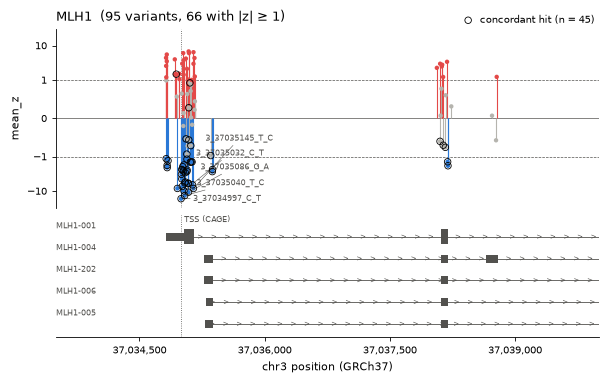

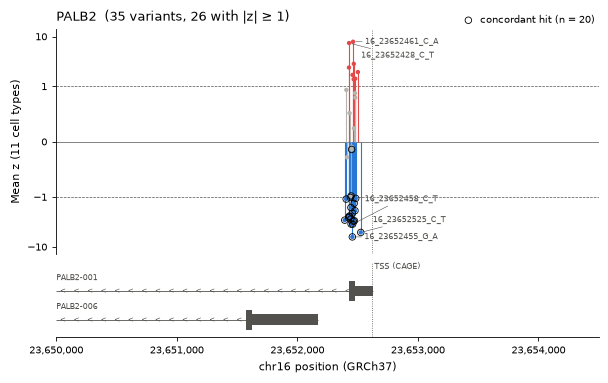

In [31]:
BREAST_EPI = ['Lumsec_major', 'Lumsec_myo', 'Lumsec_basal', 'Lumsec_KIT', 'Lumsec_lac',
              'Lumsec_prol', 'Lumsec_HLA', 'LummHR_major', 'LummHR_SCGB', 'LummHR_active', 'basal']

# mean z across all cell types, zoomed on the promoter
fig, _ = plot_gene_track("MLH1", ann_vars, highlight=SELECT_SNPs, window=(37033500, 37040000))

# mean z across breast epithelial cell types
fig, _ = plot_gene_track("PALB2", ann_vars, celltypes=BREAST_EPI, highlight=SELECT_SNPs,
                         window=(23650000, 23654500))
# fig.savefig("track_PALB2.pdf", dpi=600, bbox_inches="tight")